In [7]:
import numpy as np
import netCDF4 as nc4
import pickle as pkl
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from astropy.time import Time
from scipy.interpolate import interp1d

In [8]:

# Pain

a_coef = [2.000365,3.102241,4.666084,6.827977,9.746966,13.605424,18.608931,24.985718,32.98571,42.879242,54.955463,69.520576,86.895882,107.415741,131.425507,159.279404,191.338562,227.968948,269.539581,316.420746,
368.982361,427.592499,492.616028,564.413452,643.339905,729.744141,823.967834,926.34491,1037.201172,1156.853638,1285.610352,1423.770142,1571.622925,1729.448975,1897.519287,2076.095947,2265.431641,2465.770508,2677.348145,
2900.391357,3135.119385,3381.743652,3640.468262,3911.490479,4194.930664,4490.817383,4799.149414,5119.89502,5452.990723,5798.344727,6156.074219,6526.946777,6911.870605,7311.869141,7727.412109,8159.354004,8608.525391,9076.400391,
9562.682617,10065.97852,10584.63184,11116.66211,11660.06738,12211.54785,12766.87305,13324.66895,13881.33106,14432.13965,14975.61523,15508.25684,16026.11523,16527.32227,17008.78906,17467.61328,17901.62109,18308.43359,18685.71875,
19031.28906,19343.51172,19620.04297,19859.39063,20059.93164,20219.66406,20337.86328,20412.30859,20442.07813,20425.71875,20361.81641,20249.51172,20087.08594,19874.02539,19608.57227,19290.22656,18917.46094,18489.70703,18006.92578,17471.83984,
16888.6875,16262.04688,15596.69531,14898.45313,14173.32422,13427.76953,12668.25781,11901.33984,11133.30469,10370.17578,9617.515625,8880.453125,8163.375,7470.34375,6804.421875,6168.53125,5564.382813,4993.796875,4457.375,3955.960938,
3489.234375,3057.265625,2659.140625,2294.242188,1961.5,1659.476563,1387.546875,1143.25,926.507813,734.992188,568.0625,424.414063,302.476563,202.484375,122.101563,62.78125,22.835938,3.757813,0,0]

b_coef = [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.000007,0.000024,0.000059,0.000112,0.000199,0.00034,0.000562,0.00089,0.001353,0.001992,0.002857,0.003971,0.005378,
0.007133,0.009261,0.011806,0.014816,0.018318,0.022355,0.026964,0.032176,0.038026,0.044548,0.051773,0.059728,0.068448,0.077958,0.088286,0.099462,0.111505,0.124448,0.138313,0.153125,0.16891,0.185689,0.203491,0.222333,0.242244,0.263242,
0.285354,0.308598,0.332939,0.358254,0.384363,0.411125,0.438391,0.466003,0.4938,0.521619,0.549301,0.576692,0.603648,0.630036,0.655736,0.680643,0.704669,0.727739,0.749797,0.770798,0.790717,0.809536,0.827256,0.843881,0.859432,0.873929,
0.887408,0.8999,0.911448,0.922096,0.931881,0.94086,0.949064,0.95655,0.963352,0.969513,0.975078,0.980072,0.984542,0.9885,0.991984,0.995003,0.99763,1]


In [9]:

E5_file = '/glade/u/home/wsmith/ASM_Plotter/Analysis_Files/era5.oper.fc.ml.hrly.20220818.235009.nc'
E5_sfcfile = '/gdex/data/d633000/e5.oper.an.sfc/202208/e5.oper.an.sfc.128_134_sp.ll025sc.2022080100_2022083123.nc'
ref1970 = datetime(1970, 1, 1, 0, 0)
ref1900 = datetime(1900, 1, 1, 0, 0, 0)

conv_dom = [110,122,36,42]
lev_index = 78  # model level index ~250 hPa for grabbing the max value
prs_grid = np.arange(10,1001,5)

t_rng = [0,11]  # Time indices we want to include (code should make this inclusive)


In [10]:

E5nc = nc4.Dataset(E5_file)
E5lon = E5nc.variables['longitude'][:]
E5lat = E5nc.variables['latitude'][:]
#E5prs = E5nc.variables['model_level'][:]
E5sec = E5nc.variables['valid_time'][:]  # This is in minutes since 0130UTC for some reason

i = np.where((E5lon >= conv_dom[0]) & (E5lon <= conv_dom[1]))[0]
j = np.where((E5lat >= conv_dom[2]) & (E5lat <= conv_dom[3]))[0]

E5sfcnc = nc4.Dataset(E5_sfcfile)
E5sfchr = E5sfcnc.variables['time'][:]

E5sfc_jd = []
for t in range(len(E5sfchr)):

    dt = ref1900 + timedelta(hours=int(E5sfchr[t]))
    E5sfc_jd.append(Time(dt).jd)
    

In [11]:

MUMF_profs = np.zeros((1,len(prs_grid)))-999

for t in range(t_rng[1] - t_rng[0] + 1):

    curr_dt = ref1970 + timedelta(seconds=int(E5sec[t]))
    curr_jd = Time(curr_dt).jd
    sfc_tind = E5sfc_jd.index(curr_jd)

    E5_MUMFlev = np.squeeze(E5nc.variables['mumf'][t,lev_index,j,i])
    E5_MUMF = np.squeeze(E5nc.variables['mumf'][t,:,j,i])
    E5sfcPS = E5sfcnc.variables['SP'][sfc_tind,j,i]

    jj,ii = np.unravel_index(E5_MUMFlev.argmax(), E5_MUMFlev.shape)

    curr_PS = E5sfcPS[jj,ii]
    curr_plev = (np.asarray(a_coef) + np.asarray(b_coef)*curr_PS)/100.
    curr_MUMF = E5_MUMF[:,jj,ii]

    f_z = interp1d(curr_plev, curr_MUMF, bounds_error=False, fill_value=-999) 
    MUMF_profs = np.append(MUMF_profs, f_z(prs_grid)[None,:]*3600., axis=0)

    print(np.shape(MUMF_profs))

MUMF_meanprof = np.mean(MUMF_profs[1:,:], axis=0)


(2, 199)
(3, 199)
(4, 199)
(5, 199)
(6, 199)
(7, 199)
(8, 199)
(9, 199)
(10, 199)
(11, 199)
(12, 199)
(13, 199)


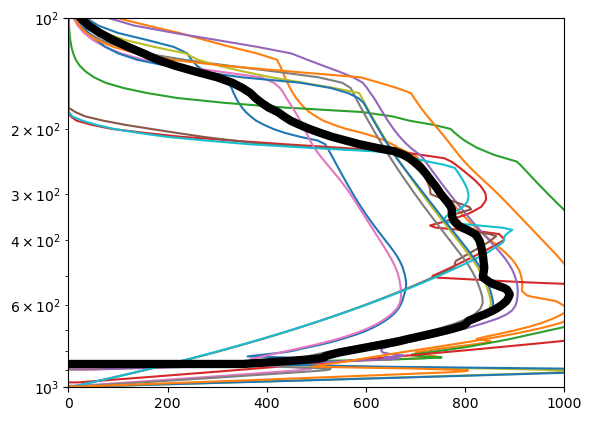

In [18]:

#print(MUMF_meanprof)

for t in range(12):
    plt.plot(MUMF_profs[t+1], prs_grid)
plt.plot(MUMF_meanprof, prs_grid, color='k', linewidth = 6)
plt.ylim(1000,100)
plt.yscale('log')
plt.xlim(0,1000)

with open('/glade/u/home/wsmith/ASM_Plotter/Analysis_Files/E5_MUMF.pkl', 'wb') as f:
    pkl.dump((MUMF_meanprof, prs_grid),f)
